# Supplementary Figure 1

Last-saccade behavioral data from the memory-guided visual search task (session 2). Accompanies Figure 2. Reads `dataframes/search_data_all.csv`, produced by `figure2.ipynb` -- run that notebook first.

In [1]:
import os.path as op
import os
os.environ.setdefault("OUTDATED_IGNORE", "1")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg

from mgvs_release import config
from mgvs_release.plotting import setup_style, push_to_back, save_fig
from mgvs_release.stats import paired_ttest

In [2]:
setup_style()

In [3]:
subjects = config.SUBJECTS

save_dir = '../plots/'
dataframes_dir = '../dataframes/'
data = pd.read_csv(op.join(dataframes_dir, 'search_data_all.csv'))

## Supplementary Fig. 1A: Search accuracy by condition (last saccade)

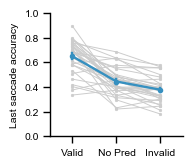

In [4]:
f, ax = plt.subplots(1, 1, figsize=(1.95, 1.7))

plot_data = data.query(
    "trial!=1 & sacc_last==True"
).groupby(['subject', 'target_validity']).mean(numeric_only=True).reset_index()

sns.pointplot(y='warp_resp', x='target_validity', hue='subject', errorbar=('ci', 0),
                 hue_order=subjects, linewidth=.7, palette=['#cccccc'] * len(subjects),
                 order=['valid', 'nopred', 'invalid'],
                 zorder=-100, ax=ax,
                 data=plot_data)
push_to_back(ax)

sns.pointplot(y='warp_resp', x='target_validity', errorbar='se',
                 color='#3690c0',
                 order=['valid', 'nopred', 'invalid'],
                 linewidth=1.7, ms=2.7,
                 ax=ax,
                 data=plot_data)

ax.set(ylabel='Last saccade accuracy', xlabel='',
       ylim=[0, 1], xticks=range(3), xticklabels=['Valid', 'No Pred', 'Invalid'])
ax.legend_ = None
sns.despine()
f.tight_layout()
save_fig(f, op.join(save_dir, 'sfig1a'))

In [5]:
cond_subj_mean = data.query(
    "trial!=1 & sacc_last==True"
).groupby(['subject', 'target_validity']).mean(numeric_only=True).reset_index()
cond_subj_mean.groupby(['target_validity'])['warp_resp'].mean()

target_validity
invalid    0.378451
nopred     0.444990
valid      0.648951
Name: warp_resp, dtype: float64

In [6]:
# Effect of target validity on accuracy
pg.rm_anova(data=cond_subj_mean, dv='warp_resp', within=['target_validity'], subject='subject', effsize='np2')

,Source,ddof1,ddof2,F,p-unc,p-GG-corr,np2,eps,sphericity,W-spher,p-spher
0,target_validity,2,62,65.896266,4.536221e-16,5.306737e-11,0.68007,0.632425,False,0.418785,0.000002


In [7]:
# Valid condition has greater accuracy than no prediction condition
paired_ttest(cond_subj_mean.query("target_validity=='valid'")['warp_resp'],
             cond_subj_mean.query("target_validity=='nopred'")['warp_resp'])

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,7.338898,31,two-sided,2.920406e-08,"[0.15, 0.26]",1.623086,4.741e+05,1.0


In [8]:
# Valid condition has greater accuracy than invalid condition
paired_ttest(cond_subj_mean.query("target_validity=='valid'")['warp_resp'],
             cond_subj_mean.query("target_validity=='invalid'")['warp_resp'])

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,9.075795,31,two-sided,3.080887e-10,"[0.21, 0.33]",2.237035,3.466e+07,1.0


In [9]:
# Invalid condition has lower accuracy than no prediction condition
paired_ttest(cond_subj_mean.query("target_validity=='invalid'")['warp_resp'],
             cond_subj_mean.query("target_validity=='nopred'")['warp_resp'])

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,-5.466226,31,two-sided,0.000006,"[-0.09, -0.04]",0.61703,3540.343,0.922263


## Supplementary Fig. 1B: Interference in valid trials, distribution (last saccade)

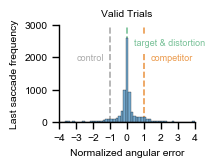

In [10]:
f, ax = plt.subplots(1, 1, figsize=(2.1, 1.7))
plot_data = data.query("trial!=1 & sacc_last==True & target_validity=='valid' & targ_comp_dist!=180")
g = sns.histplot(x='norm_err_toward', alpha=1, ax=ax,
                color='#74a9cf', binwidth=.15,
                data=plot_data)
ax.axvline(x=0, c="#3fa76cb3", ls="--", zorder=-100)
ax.axvline(x=1, c="#e37103b3", ls="--", zorder=-100)
ax.axvline(x=-1, c="#aaaaaa", ls="--", zorder=-100)

ax.set(xlim=[-4, 4], xticks=np.arange(-4, 5), ylim=[0, 3000])
ax.text(0.4, 2360, 'target & distortion', backgroundcolor='1', c='#3fa76cb3', fontsize=6.5)
ax.text(1.4, 1900, 'competitor', c="#e37103b3", fontsize=6.5)
ax.text(-2.95, 1900, 'control', c="#aaaaaa", fontsize=6.5)
ax.set(xlabel='Normalized angular error', ylabel='Last saccade frequency',
      title='Valid Trials')
sns.despine()
f.tight_layout()
save_fig(f, op.join(save_dir, 'sfig1b'))

## Supplementary Fig. 1C: Interference in valid trials, competitor vs control (last saccade)

In [11]:
# Control location cannot be defined for 180 degree pairs
subj_mean_no180 = data.query(
    "trial!=1 & sacc_last==True & target_validity=='valid' & targ_comp_dist!=180"
).groupby(['subject']).mean(numeric_only=True).reset_index()

In [12]:
# More competitor than control saccades
paired_ttest(subj_mean_no180['comp_resp'], subj_mean_no180['cont_resp'])

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,5.049395,31,two-sided,0.000019,"[0.02, 0.05]",1.216444,1181.319,1.0


In [13]:
comp_cont_df = subj_mean_no180.melt(id_vars=['subject',],
                                       value_vars=['comp_resp', 'cont_resp'],
                                       var_name='resp_cat', value_name='prob')

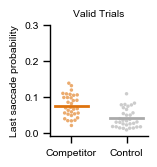

In [14]:
pal = ['#de730e', '#aaaaaa']
f, ax = plt.subplots(1, 1, figsize=(1.6, 1.7))

sns.swarmplot(x='resp_cat', y='prob', hue='resp_cat', palette=pal, size=2.5, alpha=.6,
                   legend=False, data=comp_cont_df, ax=ax)

comp_mean = subj_mean_no180['comp_resp'].mean()
control_mean = subj_mean_no180['cont_resp'].mean()
ax.plot([-.3, .3], [comp_mean, comp_mean], c=pal[0], lw=2)
ax.plot([1-.3, 1+.3], [control_mean, control_mean], c=pal[1], lw=2)

ax.legend_ = None
ax.set(ylim=[-.01,.3], xlabel='', ylabel='Last saccade probability', title='Valid Trials',
       xticks=range(2), xticklabels=['Competitor', 'Control'])
plt.gcf().tight_layout()
sns.despine()

save_fig(f, op.join(save_dir, 'sfig1c'))

## Supplementary Fig. 1D: Effect of target-competitor distance (last saccade)

In [15]:
# Above analysis separately by target-competitor distance
subj_mean_dist_no180 = data.query(
    "trial!=1 & sacc_last==True & target_validity=='valid' & targ_comp_dist!=180"
).groupby(['subject', 'targ_comp_dist']).mean(numeric_only=True).reset_index()
comp_cont_dist_df = subj_mean_dist_no180.melt(id_vars=['subject', 'targ_comp_dist'],
                                       value_vars=['comp_resp', 'cont_resp'],
                                       var_name='resp_cat', value_name='prob')

In [16]:
# Interaction between competitor/control saccades and target-competitor distance
pg.rm_anova(data=comp_cont_dist_df, dv='prob', subject='subject', effsize='np2',
            within=['resp_cat', 'targ_comp_dist'])

,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,np2,eps
0,resp_cat,0.059928,1,31,0.059928,25.680647,0.000018,0.000018,0.453076,1.000000
1,targ_comp_dist,0.033140,2,62,0.016570,13.315919,0.000015,0.000062,0.300477,0.830934
2,resp_cat * targ_comp_dist,0.000471,2,62,0.000236,0.264720,0.768283,0.761607,0.008467,0.969762


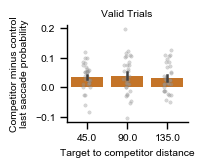

In [17]:
subj_mean_dist_no180['comp_cont_resp_diff'] = (subj_mean_dist_no180['comp_resp'] -
                                                subj_mean_dist_no180['cont_resp'])

pal = ['#de730e', '#aaaaaa']
f, ax = plt.subplots(1, 1, figsize=(2, 1.7))

sns.barplot(x='targ_comp_dist', y='comp_cont_resp_diff',
           color=pal[0], errorbar='se', err_kws={'zorder': 3},
            data=subj_mean_dist_no180, ax=ax)

sns.stripplot(x='targ_comp_dist', y='comp_cont_resp_diff',
            color='.6', zorder=2,
            size=2.5, alpha=.4, edgecolor=".5", linewidth=.2,
            data=subj_mean_dist_no180, ax=ax)


ax.legend_ = None
ax.set(ylabel='Competitor minus control\nlast saccade probability', title='Valid Trials',
       xlabel='Target to competitor distance')
sns.despine()
plt.gcf().tight_layout()

save_fig(f, op.join(save_dir, 'sfig1d'))